# 01 - Data Cleaning & EDA : Online Retail II

Goal: load the raw transactions, inspect data quality issues, document every cleaning decision with row counts, and save a clean dataset for RFM, market basket and recommendation notebooks.

## 1. Load data 

In [1]:
import pandas as pd
import numpy as np
from pathlib  import Path

pd.set_option("display.max_columns", 50)

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RAW_XLSX = RAW_DIR / "online_retail_II.xlsx"
RAW_PARQUET = RAW_DIR / "online_retail_raw.parquet"

print(PROJECT_DIR)
print("Excel found:", RAW_XLSX.exists())

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

C:\Users\user\Desktop\market-basket-next-product
Excel found: True


In [2]:
%%time
sheets = pd.read_excel(RAW_XLSX, sheet_name=None) # dict: {sheet name: DataFrame}

frames = []
for name, sheet_df in sheets.items():
    print(f"{name}: {sheet_df.shape}")
    frames.append(sheet_df.assign(sheet=name))   # add column with sheet name

df = pd.concat(frames, ignore_index = True)    # stack sheets vertically
print("Combined:", df.shape)
df.head()

Year 2009-2010: (525461, 8)
Year 2010-2011: (541910, 8)
Combined: (1067371, 9)
CPU times: total: 3min 14s
Wall time: 3min 16s


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010


In [3]:
df = df.astype({
    "Invoice":     "string",
    "StockCode":   "string",
    "Description": "string",
    "Country":     "string",
    "sheet":       "string",
    "Customer ID": "Int64",
})
print(df.dtypes)

df.to_parquet(RAW_PARQUET, index=False)
print("Saved:", RAW_PARQUET.name, f"{RAW_PARQUET.stat().st_size / 1e6:.1f} MB")

Invoice                string
StockCode              string
Description            string
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             Int64
Country                string
sheet                  string
dtype: object
Saved: online_retail_raw.parquet 7.2 MB


In [4]:
%%time
df = pd.read_parquet(RAW_PARQUET)
print(df.shape)
df.dtypes

(1067371, 9)
CPU times: total: 500 ms
Wall time: 159 ms


Invoice                string
StockCode              string
Description            string
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             Int64
Country                string
sheet                  string
dtype: object

## 2. Data quality checks 

In [5]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "pct":     (df.isna().mean() * 100).round(2),
})
missing

,missing,pct
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00
sheet,0,0.00


Customer ID is missing in 22.8% of lines (guest checkouts). These rows are kept for market basket analysis (baskets are defined by Invoice) but excluded from RFM and recommendations. Description is missing in 0.4%.

In [6]:
print(df.groupby("sheet")["InvoiceDate"].agg(["min", "max", "count"]))

start_2nd = df.loc[df["sheet"] == "Year 2010-2011", "InvoiceDate"].min()
overlap = df[(df["sheet"] == "Year 2009-2010") & (df["InvoiceDate"] >= start_2nd)]
print("\nRows in sheet 1 dated after sheet 2 starts:", len(overlap))

                               min                 max   count
sheet                                                         
Year 2009-2010 2009-12-01 07:45:00 2010-12-09 20:01:00  525461
Year 2010-2011 2010-12-01 08:26:00 2011-12-09 12:50:00  541910

Rows in sheet 1 dated after sheet 2 starts: 22523


In [7]:
print("Full duplicates (incl. sheet column):", df.duplicated().sum())
print("Duplicates ignoring sheet column:   ", df.drop(columns="sheet").duplicated().sum())

Full duplicates (incl. sheet column): 12133
Duplicates ignoring sheet column:    34335


In [8]:
in_overlap = (df["sheet"] == "Year 2009-2010") & (df["InvoiceDate"] >= start_2nd)
df_no_overlap = df[~in_overlap]

print("Rows after removing overlap:", len(df_no_overlap))
print("Duplicates left:", df_no_overlap.drop(columns="sheet").duplicated().sum())

Rows after removing overlap: 1044848
Duplicates left: 11812


The two sheets overlap on 1–9 Dec 2010 (22,523 rows). Removing them reduces duplicates from 34,335 to 11,812, a drop of exactly 22,523, so every overlap row is an exact copy. Decision: take this period from sheet 2 only. The remaining 11,812 within-sheet exact duplicates are double entries → drop.

In [9]:
is_cancel = df["Invoice"].str.startswith("C")
neg_qty   = df["Quantity"] < 0
bad_price = df["Price"] <= 0

print("Cancellation invoices (C...):", is_cancel.sum())
print("Quantity < 0:               ", neg_qty.sum())
print("Price <= 0:                 ", bad_price.sum())

print("\nCancellation vs negative quantity:")
print(pd.crosstab(is_cancel, neg_qty, rownames=["cancel"], colnames=["qty<0"]))

print("\nInvoice prefixes that are not plain numbers:")
print(df.loc[~df["Invoice"].str.isdigit(), "Invoice"].str[0].value_counts())

print("\nShare of Price<=0 rows with missing Description:",
      round(df.loc[bad_price, "Description"].isna().mean(), 3))

Cancellation invoices (C...): 19494
Quantity < 0:                22950
Price <= 0:                  6207

Cancellation vs negative quantity:
qty<0     False  True 
cancel                
False   1044420   3457
True          1  19493

Invoice prefixes that are not plain numbers:
Invoice
C    19494
A        6
Name: count, dtype: int64[pyarrow]

Share of Price<=0 rows with missing Description: 0.706


In [10]:
df[neg_qty & ~is_cancel].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,sheet
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,<NA>,United Kingdom,Year 2009-2010
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,<NA>,United Kingdom,Year 2009-2010
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,<NA>,United Kingdom,Year 2009-2010
470,489521,21646,<NA>,-50,2009-12-01 11:44:00,0.0,<NA>,United Kingdom,Year 2009-2010
3114,489655,20683,<NA>,-44,2009-12-01 17:26:00,0.0,<NA>,United Kingdom,Year 2009-2010
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,<NA>,United Kingdom,Year 2009-2010
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,<NA>,United Kingdom,Year 2009-2010
4296,489806,18010,<NA>,-770,2009-12-02 12:42:00,0.0,<NA>,United Kingdom,Year 2009-2010
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,<NA>,United Kingdom,Year 2009-2010
4566,489821,85049G,<NA>,-240,2009-12-02 13:25:00,0.0,<NA>,United Kingdom,Year 2009-2010


19,494 cancellation invoices (C…), all but one with negative quantity → excluded (a basket is what the customer bought; netting returns is out of scope). 3,457 negative-quantity rows without C are warehouse adjustments (damages, lost, short), price 0, no customer → drop. 6 “A” invoices are bad-debt entries → drop. Price ≤ 0 rows are mostly blank descriptions → not sales.

In [11]:
print(df["StockCode"].nunique(), "vs uppercased:", df["StockCode"].str.upper().nunique())

5305 vs uppercased: 5132


In [12]:
is_std = df["StockCode"].str.match(r"^\d{5}[A-Za-z]*$")
print("Rows with non-standard StockCode:", (~is_std).sum(),
      "| unique codes:", df.loc[~is_std, "StockCode"].nunique())

(df[~is_std]
 .groupby("StockCode")
 .agg(rows=("Invoice", "size"),
      example=("Description", "first"),
      avg_price=("Price", "mean"))
 .sort_values("rows", ascending=False))

Rows with non-standard StockCode: 6094 | unique codes: 63


,rows,example,avg_price
StockCode,,,
POST,2122,POSTAGE,32.623322
DOT,1446,DOTCOM POSTAGE,223.144876
M,1421,Manual,528.776284
C2,282,CARRIAGE,49.460993
D,177,Discount,72.867288
S,104,SAMPLES,60.956731
BANK CHARGES,102,Bank Charges,359.034422
ADJUST,67,Adjustment by john on 26/01/2010 16,163.591343
AMAZONFEE,43,AMAZON FEE,7646.089302


173 codes differ only by case (85123a vs 85123A) → uppercase StockCode. The 63 non-standard codes fall into three groups: fees/admin (POST, DOT, M, C2, C3, D, S, BANK CHARGES, AMAZONFEE, CRUK, B, ADJUST*, TEST*) → drop; gift vouchers (GIFT*) → drop; DCGS*, PADS, SP1002, 47503J are real products → keep. So the rule is an explicit list, not the regex.

In [13]:
print("Unique StockCodes:  ", df["StockCode"].nunique())
print("Unique Descriptions:", df["Description"].nunique())

desc_per_code = df.groupby("StockCode")["Description"].nunique()
print("Codes with >1 description:", (desc_per_code > 1).sum())

worst = desc_per_code.idxmax()
print(f"\nExample — {worst}:")
print(df.loc[df["StockCode"] == worst, "Description"].value_counts())

Unique StockCodes:   5305
Unique Descriptions: 5698
Codes with >1 description: 1232

Example — 20713:
Description
JUMBO BAG OWLS                  1372
missing                            1
wrongly marked. 23343 in box       1
wrongly coded-23343                1
found                              1
Found                              1
wrongly marked 23343               1
Marked as 23343                    1
wrongly coded 23343                1
Name: count, dtype: int64[pyarrow]


In [14]:
has_lower = df["Description"].str.contains(r"[a-z]", na=False)
print("Descriptions with lowercase letters:", has_lower.sum())
df.loc[has_lower, "Description"].value_counts().head(30)

Descriptions with lowercase letters: 5967


Description
Manual                                 1426
BAG 250g SWIRLY MARBLES                 598
BAG 125g SWIRLY MARBLES                 596
POLYESTER FILLER PAD 40x40cm            398
POLYESTER FILLER PAD 45x45cm            372
3 TRADITIONAl BISCUIT CUTTERS  SET      268
BAG 500g SWIRLY MARBLES                 240
FRENCH BLUE METAL DOOR SIGN No          186
Discount                                177
check                                   162
Bank Charges                             96
damages                                  84
damaged                                  81
ESSENTIAL BALM 3.5g TIN IN ENVELOPE      80
Next Day Carriage                        80
POLYESTER FILLER PAD 45x30cm             65
POLYESTER FILLER PAD 65CMx65CM           52
POLYESTER FILLER PAD 30CMx30CM           52
FRENCH BLUE METAL DOOR SIGN, No          48
NUMBER TILE COTTAGE GARDEN No            42
NUMBER TILE VINTAGE FONT No              39
Adjustment by john on 26/01/2010 16      38
FOLK ART GREETING CA

In [15]:
df.loc[df["StockCode"].str.upper() == "23444", "Description"].value_counts()

Description
Next Day Carriage    80
Name: count, dtype: int64[pyarrow]

Lowercase descriptions include real products (BAG 250g, 40x40cm), so lowercase is a hint for junk, not a rule. Code 23444 is “Next Day Carriage” in all 80 rows → treated as a fee.

## 3. Cleaning 

In [16]:
NON_PRODUCT_CODES = {"POST", "DOT", "M", "C2", "C3", "D", "S",
                     "BANK CHARGES", "AMAZONFEE", "CRUK", "B", "23444"}
NON_PRODUCT_PATTERN = r"^(ADJUST|TEST|GIFT)"      # ADJUST2, TEST002, GIFT_0001_30...

clean = df.copy()
log = [{"step": "0. Raw data (both sheets)", "rows_removed": 0, "rows_left": len(clean)}]

def drop(data, mask, step):
    """Remove rows where mask is True and record how many were removed."""
    removed = int(mask.sum())
    data = data[~mask]
    log.append({"step": step, "rows_removed": removed, "rows_left": len(data)})
    return data

# 1. Overlap: take Dec 1–9 2010 from sheet 2 only
clean = drop(clean, (clean["sheet"] == "Year 2009-2010") & (clean["InvoiceDate"] >= start_2nd),
             "1. Sheet overlap (Dec 2010 duplicated in both sheets)")

# Normalise codes before checking duplicates (85123a = 85123A)
clean["StockCode"] = clean["StockCode"].str.strip().str.upper()

clean = drop(clean, clean.drop(columns="sheet").duplicated(),      "2. Exact duplicate rows")
clean = drop(clean, clean["Invoice"].str.startswith("C"),           "3. Cancellations (C invoices)")
clean = drop(clean, clean["Invoice"].str.startswith("A"),           "4. Bad-debt adjustments (A invoices)")
clean = drop(clean, clean["Quantity"] <= 0,                         "5. Quantity <= 0 (stock adjustments)")
clean = drop(clean, clean["Price"] <= 0,                            "6. Price <= 0")
clean = drop(clean, clean["StockCode"].isin(NON_PRODUCT_CODES)
                    | clean["StockCode"].str.match(NON_PRODUCT_PATTERN),
             "7. Non-product codes (postage, fees, vouchers, tests)")

# 8. Purchases reversed by a matching cancellation (same customer, product, quantity)
cancel_lines = (df[df["Invoice"].str.startswith("C") & df["Customer ID"].notna()]
                .drop(columns="sheet").drop_duplicates().copy())   # drop overlap copies
cancel_lines["StockCode"] = cancel_lines["StockCode"].str.strip().str.upper()
cancel_lines["Quantity"] = -cancel_lines["Quantity"]

keys = ["Customer ID", "StockCode", "Quantity"]
p = (clean.loc[clean["Customer ID"].notna(), keys + ["InvoiceDate"]]
          .rename_axis("row_id").reset_index())
c = cancel_lines[keys + ["InvoiceDate"]].copy()
for d in (p, c):
    d["Customer ID"] = d["Customer ID"].astype("int64")
    d["StockCode"] = d["StockCode"].astype(str)

matched = pd.merge_asof(c.sort_values("InvoiceDate"), p.sort_values("InvoiceDate"),
                        on="InvoiceDate", by=keys, direction="backward"
                        ).dropna(subset=["row_id"])

clean = drop(clean, clean.index.isin(matched["row_id"]),
             "8. Purchases reversed by a matching cancellation")


clean = clean.drop(columns="sheet").reset_index(drop=True)

cleaning_log = pd.DataFrame(log)
cleaning_log

,step,rows_removed,rows_left
0,0. Raw data (both sheets),0,1067371
1,1. Sheet overlap (Dec 2010 duplicated in both ...,22523,1044848
2,2. Exact duplicate rows,11812,1033036
3,3. Cancellations (C invoices),19104,1013932
4,4. Bad-debt adjustments (A invoices),6,1013926
5,5. Quantity <= 0 (stock adjustments),3393,1010533
6,6. Price <= 0,2621,1007912
7,"7. Non-product codes (postage, fees, vouchers,...",4634,1003278
8,8. Purchases reversed by a matching cancellation,6179,997099


64,093 rows removed (6.0%): 1,067,371 → 1,003,278. Rules are applied in order, so each count excludes rows removed earlier (e.g., Price ≤ 0 removes 2,621, not 6,207).

In [17]:
print("Missing values:\n", clean.isna().sum(), "\n")
print("Customer ID missing share:", round(clean["Customer ID"].isna().mean(), 3))
print("Unique StockCodes:", clean["StockCode"].nunique())

desc_per_code = clean.groupby("StockCode")["Description"].nunique()
print("Codes with >1 description:", (desc_per_code > 1).sum())

has_lower = clean["Description"].str.contains(r"[a-z]", na=False)
clean.loc[has_lower, "Description"].value_counts().head(20)

Missing values:
 Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    226761
Country             0
dtype: int64 

Customer ID missing share: 0.227
Unique StockCodes: 4716
Codes with >1 description: 621


Description
BAG 125g SWIRLY MARBLES                573
BAG 250g SWIRLY MARBLES                571
POLYESTER FILLER PAD 40x40cm           375
POLYESTER FILLER PAD 45x45cm           353
3 TRADITIONAl BISCUIT CUTTERS  SET     250
BAG 500g SWIRLY MARBLES                227
FRENCH BLUE METAL DOOR SIGN No         172
ESSENTIAL BALM 3.5g TIN IN ENVELOPE     73
POLYESTER FILLER PAD 45x30cm            61
POLYESTER FILLER PAD 30CMx30CM          51
POLYESTER FILLER PAD 65CMx65CM          48
FRENCH BLUE METAL DOOR SIGN, No         47
NUMBER TILE COTTAGE GARDEN No           40
NUMBER TILE VINTAGE FONT No             36
FOLK ART GREETING CARD,pack/12          28
THE KING GIFT BAG 25x24x12cm            13
Hypochondriac Pill Stress Ball           9
Dad's Cab Electronic Meter               9
POLYESTER FILLER PAD 60x40cm             6
Dr. Jam's Arouzer Stress Ball            5
Name: count, dtype: int64[pyarrow]

In [18]:
big = clean.nlargest(10, "Quantity")[["Invoice", "StockCode", "Description",
                                      "Quantity", "Price", "Customer ID", "InvoiceDate"]]

cancels = df[df["Invoice"].str.startswith("C")].copy()
cancels["StockCode"] = cancels["StockCode"].str.upper()
cancels["Quantity"] = -cancels["Quantity"]          # make positive to match purchases

big.merge(cancels[["StockCode", "Quantity", "Customer ID", "Invoice", "InvoiceDate"]],
          on=["StockCode", "Quantity", "Customer ID"],
          how="left", suffixes=("", "_cancel"))

,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate,Invoice_cancel,InvoiceDate_cancel
0,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,13902,2010-02-15 11:57:00,<NA>,NaT
1,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902,2010-03-17 13:09:00,<NA>,NaT
2,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902,2010-03-17 13:09:00,<NA>,NaT
3,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,13902,2010-03-17 13:09:00,<NA>,NaT
4,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,13902,2010-03-17 13:09:00,<NA>,NaT
5,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,17940,2010-03-23 15:36:00,<NA>,NaT
6,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,17940,2010-03-23 15:36:00,<NA>,NaT
7,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,17940,2010-03-23 15:36:00,<NA>,NaT
8,502269,21981,PACK OF 12 WOODLAND TISSUES,10000,0.25,17940,2010-03-23 15:36:00,<NA>,NaT
9,498152,85220,SMALL FAIRY CAKE FRIDGE MAGNETS,9456,0.30,13902,2010-02-17 10:51:00,<NA>,NaT


In [19]:
multi = desc_per_code[desc_per_code > 1].sort_values(ascending=False)
for code in multi.index[:5]:
    print(code)
    print(clean.loc[clean["StockCode"] == code, "Description"].value_counts(), "\n")

20685
Description
DOORMAT RED RETROSPOT      894
DOOR MAT RED SPOT          410
RED SPOTTY COIR DOORMAT    207
DOORMAT RED SPOT           207
Name: count, dtype: int64[pyarrow] 

22344
Description
PARTY PIZZA DISH PINK POLKADOT       88
PARTY PIZZA DISH PINK RETROSPOT      24
PARTY PIZZA DISH PINK WHITE SPOT     19
PARTY PIZZA DISH PINK+WHITE SPOT      2
Name: count, dtype: int64[pyarrow] 

22345
Description
PARTY PIZZA DISH BLUE POLKADOT       82
PARTY PIZZA DISH BLUE RETROSPOT      28
PARTY PIZZA DISH BLUE WHITE SPOT     17
PARTY PIZZA DISH BLUE+WHITE SPOT      2
Name: count, dtype: int64[pyarrow] 

22346
Description
PARTY PIZZA DISH GREEN POLKADOT       69
PARTY PIZZA DISH GREEN RETROSPOT      19
PARTY PIZZA DISH GREEN WHITE SPOT     15
PARTY PIZZA DISH GREEN+WHITE SPOT      1
Name: count, dtype: int64[pyarrow] 

21955
Description
DOORMAT UNION JACK GUNS AND ROSES      342
DOOR MAT UNION JACK GUNS AND ROSES     227
UNION JACK GUNS & ROSES  DOORMAT       100
  DOORMAT UNION JACK GUNS

In [20]:
clean["Revenue"] = clean["Quantity"] * clean["Price"]

In [21]:
canonical = (clean.groupby("StockCode")["Description"]
                  .agg(lambda s: s.value_counts().index[0]))   # most frequent name
clean["Description"] = clean["StockCode"].map(canonical)

print("Codes with >1 description:", clean.groupby("StockCode")["Description"].nunique().gt(1).sum())

Codes with >1 description: 0


After cleaning, 624 codes still had several descriptions: the same product renamed over time (POLKADOT → RETROSPOT → WHITE SPOT) or reworded (DOORMAT / DOOR MAT). Each code now uses its most frequent description.

## 4. EDA 

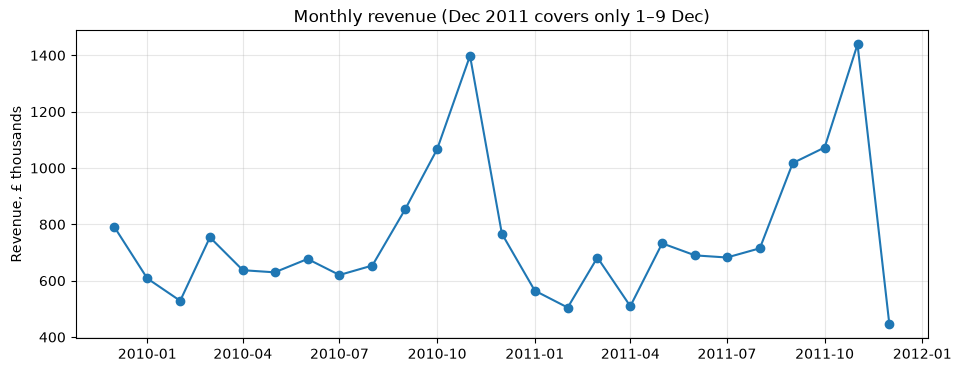

,revenue,invoices,customers
InvoiceDate,,,
2010-11-01,1398451.582,2701,1601
2010-12-01,766924.530,1542,883
2011-01-01,564732.930,1073,737
2011-02-01,504714.910,1088,756
2011-03-01,682306.560,1431,970
2011-04-01,509523.351,1225,848
2011-05-01,732637.390,1652,1051
2011-06-01,689891.680,1511,986
2011-07-01,682395.011,1445,945


In [22]:
import matplotlib.pyplot as plt

monthly = (clean.groupby(pd.Grouper(key="InvoiceDate", freq="MS"))
                .agg(revenue=("Revenue", "sum"),
                     invoices=("Invoice", "nunique"),
                     customers=("Customer ID", "nunique")))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly["revenue"] / 1e3, marker="o")
ax.set_title("Monthly revenue (Dec 2011 covers only 1–9 Dec)")
ax.set_ylabel("Revenue, £ thousands")
ax.grid(alpha=0.3)
plt.show()

monthly.tail(14)

In [23]:
guest = clean["Customer ID"].isna()

split = pd.DataFrame({
    "lines":    [(~guest).sum(), guest.sum()],
    "invoices": [clean.loc[~guest, "Invoice"].nunique(), clean.loc[guest, "Invoice"].nunique()],
    "revenue":  [clean.loc[~guest, "Revenue"].sum(),     clean.loc[guest, "Revenue"].sum()],
}, index=["registered", "guest"])

(split / split.sum() * 100).round(1)

,lines,invoices,revenue
registered,77.3,92.6,86.5
guest,22.7,7.4,13.5


In [24]:
m = monthly.copy()
m["year"], m["month"] = m.index.year, m.index.month
yoy = m[m["year"].isin([2010, 2011])].pivot(index="month", columns="year", values="revenue")
yoy["growth_%"] = ((yoy[2011] / yoy[2010] - 1) * 100).round(1)

print("Jan–Nov total growth:",
      round((yoy.loc[1:11, 2011].sum() / yoy.loc[1:11, 2010].sum() - 1) * 100, 1), "%")
yoy

Jan–Nov total growth: 2.2 %


year,2010,2011,growth_%
month,,,
1,608101.892,564732.930,-7.1
2,528711.955,504714.910,-4.5
3,753994.061,682306.560,-9.5
4,637324.072,509523.351,-20.1
5,629747.100,732637.390,16.3
6,677202.250,689891.680,1.9
7,620292.020,682395.011,10.0
8,653900.940,715056.690,9.4
9,853981.761,1017551.991,19.2


In [25]:
country = (clean.groupby("Country")
                .agg(revenue=("Revenue", "sum"),
                     invoices=("Invoice", "nunique"),
                     customers=("Customer ID", "nunique"))
                .sort_values("revenue", ascending=False))
country["rev_share_%"] = (country["revenue"] / country["revenue"].sum() * 100).round(1)
country.head(10)

,revenue,invoices,customers,rev_share_%
Country,,,,
United Kingdom,1.626503e+07,35959,5326,85.4
EIRE,6.063367e+05,576,3,3.2
Netherlands,5.462625e+05,214,22,2.9
Germany,3.799772e+05,752,107,2.0
France,2.960341e+05,595,93,1.6
Australia,1.667698e+05,86,15,0.9
Switzerland,9.332361e+04,82,22,0.5
Spain,8.509283e+04,141,38,0.4
Sweden,8.452374e+04,98,19,0.4


In [26]:
products = (clean.groupby(["StockCode", "Description"])
                 .agg(invoices=("Invoice", "nunique"),
                      revenue=("Revenue", "sum"),
                      quantity=("Quantity", "sum")))

print("Top 10 by number of invoices (how often bought):")
print(products.sort_values("invoices", ascending=False).head(10))
print("\nTop 10 by revenue:")
print(products.sort_values("revenue", ascending=False).head(10))

Top 10 by number of invoices (how often bought):
                                              invoices    revenue  quantity
StockCode Description                                                      
85123A    WHITE HANGING HEART T-LIGHT HOLDER      5431  252527.08     91356
85099B    JUMBO BAG RED RETROSPOT                 3996  181069.75     96268
22423     REGENCY CAKESTAND 3 TIER                3807  322576.57     25781
21212     PACK OF 72 RETROSPOT CAKE CASES         3106   51413.95     94108
20725     LUNCH BAG RED RETROSPOT                 3039   70266.14     39746
84879     ASSORTED COLOUR BIRD ORNAMENT           2800  128653.51     79632
47566     PARTY BUNTING                           2663  147459.98     28002
21232     STRAWBERRY CERAMIC TRINKET BOX          2424   48995.43     37731
22383     LUNCH BAG SUKI  DESIGN                  2389   43031.80     24911
20727     LUNCH BAG  BLACK SKULL.                 2340   44040.02     25573

Top 10 by revenue:
                   

count    39251.0
mean        25.1
std         42.3
min          1.0
25%          6.0
50%         15.0
75%         28.0
max       1106.0
Name: n_products, dtype: float64

Single-product invoices: 8.0%

Median by customer type:
       n_products  revenue
guest                     
False        15.0   301.26
True         19.5   183.79


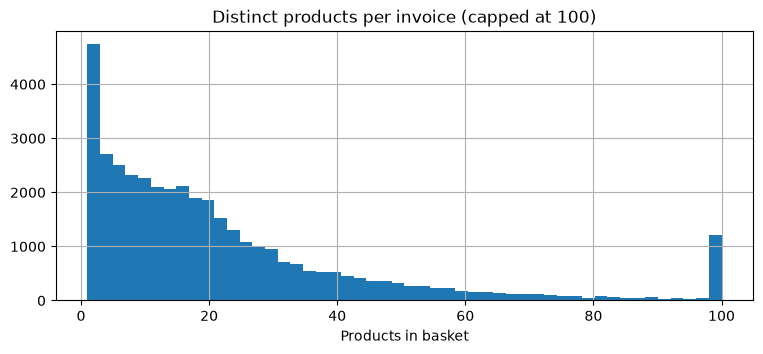

In [27]:
inv = clean.groupby("Invoice").agg(n_products=("StockCode", "nunique"),
                                   revenue=("Revenue", "sum"),
                                   customer=("Customer ID", "first"))
inv["guest"] = inv["customer"].isna()

print(inv["n_products"].describe().round(1))
print("\nSingle-product invoices:", f"{(inv['n_products'] == 1).mean():.1%}")
print("\nMedian by customer type:")
print(inv.groupby("guest")[["n_products", "revenue"]].median())

fig, ax = plt.subplots(figsize=(9, 3.5))
inv["n_products"].clip(upper=100).hist(bins=50, ax=ax)
ax.set_title("Distinct products per invoice (capped at 100)")
ax.set_xlabel("Products in basket")
plt.show()

## 5. Save

In [28]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
clean.to_parquet(PROCESSED_DIR / "online_retail_clean.parquet", index=False)
cleaning_log.to_csv(PROCESSED_DIR / "cleaning_log.csv", index=False)

print("Rows:      ", f"{len(clean):,}")
print("Invoices:  ", f"{clean['Invoice'].nunique():,}")
print("Customers: ", f"{clean['Customer ID'].nunique():,}")
print("Products:  ", f"{clean['StockCode'].nunique():,}")
print("Countries: ", clean["Country"].nunique())
print("Period:    ", clean["InvoiceDate"].min(), "→", clean["InvoiceDate"].max())

Rows:       997,099
Invoices:   39,251
Customers:  5,839
Products:   4,716
Countries:  43
Period:     2009-12-01 07:45:00 → 2011-12-09 12:50:00
